# Fine tuning VGG16

Tämä notebook toteuttaa Fine tuning VGG16 mallin.
Data, jako ja esikäsittely ovat samat kuin CNN- ja FE-notebookeissa.
Notebook lataa FE-mallin painot ja hienosäätää VGG16:n ylimmän konvoluutioblokin.
Tässä notebookissa keskitytään Modeling- ja Evaluation-vaiheisiin.

## 2. Data ja esikäsittely
Sama data ja jako kuin FE-notebookissa (224×224, preprocess_input, ei augmentaatiota).

### 2.1 Datan lataus
Koodi: image_dataset_from_directory train/val/test, 224×224.
(Ei erillistä 2.2 Datan jakaminen -osiota, koska jako on jo tehty FE-notebookissa.)

In [1]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

import numpy as np
import keras
from keras import layers
from keras.utils import image_dataset_from_directory
from keras.applications import VGG16
from keras.applications.vgg16 import preprocess_input

keras.utils.set_random_seed(42)

# Sama jako kuin FE-notebookissa: dataset_split/train, val, test
train_dataset = image_dataset_from_directory(
    "dataset_split/train",
    image_size=(224, 224),
    batch_size=32)

validation_dataset = image_dataset_from_directory(
    "dataset_split/val",
    image_size=(224, 224),
    batch_size=32,
    shuffle=False)

test_dataset = image_dataset_from_directory(
    "dataset_split/test",
    image_size=(224, 224),
    batch_size=32,
    shuffle=False)

class_names = train_dataset.class_names
num_classes = len(class_names)
print(f"Classes: {class_names}")

Found 1665 files belonging to 6 classes.
Found 355 files belonging to 6 classes.
Found 363 files belonging to 6 classes.
Classes: ['0', '1', '2', '3', '4', '5']


## 3. Mallintaminen

### 3.1 Arkkitehtuuri ja FE-painojen lataus

Malli rakennetaan täsmälleen samalla arkkitehtuurilla kuin FE-notebookissa:
preprocess_input , VGG16 (lukittu) , GlobalAveragePooling2D , Dropout(0.3) , Dense(softmax).

Painot ladataan tiedostosta fe_vgg16.weights.h5. Lähtötason (FE) testitarkkuus tarkistetaan ennen fine-tuningia.

In [2]:
# Esikoulutettu pohja ilman omaa luokittelijaa, ImageNet-painot, lukittu
base = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3),
)
base.trainable = False

# Syöte ja VGG16:n oma esikäsittely
inputs = keras.Input(shape=(224, 224, 3))
x = preprocess_input(inputs)

# Piirteet pohjasta
x = base(x, training=False)

# Oma luokittelija
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(num_classes, activation="softmax")(x)

model_ft = keras.Model(inputs, outputs)
model_ft.summary()

# Ladataan Feature Extraction painot
model_ft.load_weights("fe_vgg16.weights.h5")
print("FE-painot ladattu: fe_vgg16.weights.h5")
# Lähtötaso: FE-mallin suoritus testijoukolla
model_ft.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

test_loss_fe, test_acc_fe = model_ft.evaluate(test_dataset)
print(f"FE test loss: {test_loss_fe:.4f}")
print(f"FE test accuracy: {test_acc_fe * 100:.2f}%")

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)    │ (None, 224, 224, 3)       │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ get_item (GetItem)            │ (None, 224, 224)          │               0 │ input_layer_1[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ get_item_1 (GetItem)          │ (None, 224, 224)          │               0 │ input_layer_1[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ get_item_2 (GetItem)          │ (None, 224, 224)          │               0 │ input_layer_1[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ stack (Stack)                 │ (None, 224, 224, 3)       │               0 │ get_item[0][0],            │
│                               │                           │                 │ get_item_1[0][0],          │
│                               │                           │                 │ get_item_2[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add (Add)                     │ (None, 224, 224, 3)       │               0 │ stack[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ vgg16 (Functional)            │ (None, 7, 7, 512)         │      14,714,688 │ add[0][0]                  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ global_average_pooling2d      │ (None, 512)               │               0 │ vgg16[0][0]                │
│ (GlobalAveragePooling2D)      │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dropout (Dropout)             │ (None, 512)               │               0 │ global_average_pooling2d[… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense (Dense)                 │ (None, 6)                 │           3,078 │ dropout[0][0]              │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 14,717,766 (56.14 MB)

 Trainable params: 3,078 (12.02 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

FE-painot ladattu: fe_vgg16.weights.h5
12/12 ━━━━━━━━━━━━━━━━━━━━ 31s 3s/step - accuracy: 0.8843 - loss: 0.3635
FE test loss: 0.3635
FE test accuracy: 88.43%


### 3.2 Fine-tuning: kerrosten jäädytys

VGG16 koostuu viidestä konvoluutioblokista. Tässä avataan vain ylin blokki eli block5,
joka sisältää neljä viimeistä kerrosta. Alemmat kerrokset pysyvät lukittuina, koska ne
oppivat yleisiä piirteitä kuten reunoja ja tekstuureja, jotka kelpaavat sellaisenaan. 

In [3]:
# Avataan pohjan ylin blokki (block5 = 4 viimeistä kerrosta)
base.trainable = True
for layer in base.layers[:-4]:
    layer.trainable = False

trainable = sum(int(np.prod(w.shape)) for w in model_ft.trainable_weights)
print(f"Koulutettavia parametreja: {trainable}")

print("\nKoulutettavat kerrokset pohjassa:")
for layer in base.layers:
    if layer.trainable and layer.weights:
        print(f"  {layer.name}")

Koulutettavia parametreja: 7082502

Koulutettavat kerrokset pohjassa:
  block5_conv1
  block5_conv2
  block5_conv3


### 3.3 Uudelleenkompilointi pienellä learning ratella

Kun kerrosten trainable-asetus muuttuu, malli täytyy kompiloida uudelleen.
Koska nyt hienosäädetään vain VGG16:n ylintä blokkia, käytetään pientä
learning ratea. Näin esikoulutettuja painoja muutetaan vain vähän, eikä
opittuja piirteitä rikota.

Kokeillaan kahta eri learning ratea (1e-4 ja 1e-5) ja valitaan parempi
validaatio-lossin perusteella.

In [4]:
model_ft.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
print("Kompiloitu: Adam(learning_rate=1e-4) – Kokeilu A")

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=3, restore_best_weights=True
    ),
]

Kompiloitu: Adam(learning_rate=1e-4) – Kokeilu A


### 3.4 Koulutus

Mallia koulutetaan kahdella eri learning ratella. Kummassakin ajossa
käytetään samaa EarlyStopping-callbackia, joka pysäyttää koulutuksen
ennen 15 epochia, jos validaatio-loss ei enää parane.

In [5]:
print(" Kokeilu A: LR = 1e-4, block5 avattu ")

history_A = model_ft.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=15,
    verbose=2,
    callbacks=callbacks,
)

val_loss_A = min(history_A.history["val_loss"])
val_acc_A = max(history_A.history["val_accuracy"])
print(f"Kokeilu A: paras val_loss = {val_loss_A:.4f}, paras val_acc = {val_acc_A * 100:.2f} %")

model_ft.save_weights("ft_vgg16_A.weights.h5")
print("Painot tallennettu: ft_vgg16_A.weights.h5")

 Kokeilu A: LR = 1e-4, block5 avattu 
Epoch 1/15


C:\Users\sakar\anaconda3\envs\nn\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


53/53 - 251s - 5s/step - accuracy: 0.7874 - loss: 0.5809 - val_accuracy: 0.8563 - val_loss: 0.3794
Epoch 2/15
53/53 - 253s - 5s/step - accuracy: 0.9213 - loss: 0.2292 - val_accuracy: 0.8930 - val_loss: 0.2555
Epoch 3/15
53/53 - 265s - 5s/step - accuracy: 0.9495 - loss: 0.1508 - val_accuracy: 0.9352 - val_loss: 0.1588
Epoch 4/15
53/53 - 248s - 5s/step - accuracy: 0.9598 - loss: 0.1178 - val_accuracy: 0.9380 - val_loss: 0.1641
Epoch 5/15
53/53 - 247s - 5s/step - accuracy: 0.9766 - loss: 0.0663 - val_accuracy: 0.9493 - val_loss: 0.1148
Epoch 6/15
53/53 - 256s - 5s/step - accuracy: 0.9754 - loss: 0.0751 - val_accuracy: 0.9211 - val_loss: 0.2125
Epoch 7/15
53/53 - 247s - 5s/step - accuracy: 0.9850 - loss: 0.0410 - val_accuracy: 0.9183 - val_loss: 0.2444
Epoch 8/15
53/53 - 247s - 5s/step - accuracy: 0.9874 - loss: 0.0327 - val_accuracy: 0.9634 - val_loss: 0.0900
Epoch 9/15
53/53 - 247s - 5s/step - accuracy: 0.9808 - loss: 0.0641 - val_accuracy: 0.9437 - val_loss: 0.1225
Epoch 10/15
53/53 - 2

In [6]:
print(" Kokeilu B: LR = 1e-5, block5 avattu ")

# Ladataan FE-painot takaisin puhtaaseen lähtötilaan
model_ft.load_weights("fe_vgg16.weights.h5")

# Kompiloidaan LR = 1e-5
model_ft.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

history_B = model_ft.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=15,
    verbose=2,
    callbacks=callbacks,
)

val_loss_B = min(history_B.history["val_loss"])
val_acc_B = max(history_B.history["val_accuracy"])
print(f"Kokeilu B: paras val_loss = {val_loss_B:.4f}, paras val_acc = {val_acc_B * 100:.2f} %")

model_ft.save_weights("ft_vgg16_B.weights.h5")
print("Painot tallennettu: ft_vgg16_B.weights.h5")

 Kokeilu B: LR = 1e-5, block5 avattu 
Epoch 1/15


C:\Users\sakar\anaconda3\envs\nn\Lib\site-packages\keras\src\saving\saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_1', because it has 18 variables whereas the saved optimizer has 6 variables. 
  saveable.load_own_variables(store)


53/53 - 250s - 5s/step - accuracy: 0.8703 - loss: 0.3474 - val_accuracy: 0.8817 - val_loss: 0.2894
Epoch 2/15
53/53 - 249s - 5s/step - accuracy: 0.9213 - loss: 0.2309 - val_accuracy: 0.9070 - val_loss: 0.2490
Epoch 3/15
53/53 - 248s - 5s/step - accuracy: 0.9399 - loss: 0.1733 - val_accuracy: 0.9127 - val_loss: 0.2105
Epoch 4/15
53/53 - 247s - 5s/step - accuracy: 0.9598 - loss: 0.1277 - val_accuracy: 0.9296 - val_loss: 0.1809
Epoch 5/15
53/53 - 257s - 5s/step - accuracy: 0.9562 - loss: 0.1276 - val_accuracy: 0.9211 - val_loss: 0.1755
Epoch 6/15
53/53 - 249s - 5s/step - accuracy: 0.9748 - loss: 0.0836 - val_accuracy: 0.9408 - val_loss: 0.1734
Epoch 7/15
53/53 - 247s - 5s/step - accuracy: 0.9826 - loss: 0.0681 - val_accuracy: 0.9521 - val_loss: 0.1437
Epoch 8/15
53/53 - 248s - 5s/step - accuracy: 0.9832 - loss: 0.0607 - val_accuracy: 0.9493 - val_loss: 0.1348
Epoch 9/15
53/53 - 248s - 5s/step - accuracy: 0.9862 - loss: 0.0489 - val_accuracy: 0.9408 - val_loss: 0.1440
Epoch 10/15
53/53 - 2

In [7]:
print("\nKokeilu | LR    | Paras val_loss | Paras val_acc")
print("-" * 55)
print(f"A       | 1e-4  | {val_loss_A:>14.4f} | {val_acc_A * 100:>11.2f} %")
print(f"B       | 1e-5  | {val_loss_B:>14.4f} | {val_acc_B * 100:>11.2f} %")


Kokeilu | LR    | Paras val_loss | Paras val_acc
-------------------------------------------------------
A       | 1e-4  |         0.0900 |       96.34 %
B       | 1e-5  |         0.1114 |       95.77 %


### 3.5 Mallin valinta
Kokeilu A (LR = 1e-4) oli parempi sekä validaatio-lossilla (0.0900 vs. 0.1114) että validaatiotarkkuudella (96.34 % vs. 95.77 %). Joten valitaan kokeilu A.

In [16]:
model_ft.load_weights("ft_vgg16_A.weights.h5")
history_ft = history_A

print("Valittu malli: A (LR = 1e-4)")
print(f"  val_loss = {val_loss_A:.4f}")
print(f"  val_acc  = {val_acc_A * 100:.2f} %")

# Tallennetaan valittu malli loppuarviota varten
model_ft.save_weights("ft_vgg16.weights.h5")

Valittu malli: A (LR = 1e-4)
  val_loss = 0.0900
  val_acc  = 96.34 %


## 4. Arviointi

### 4.1 Testiarviointi

Lopullinen arvio tehdään testijoukolla.

In [17]:
test_loss_ft, test_acc_ft = model_ft.evaluate(test_dataset)
print(f"FT test loss: {test_loss_ft:.4f}")
print(f"FT test accuracy: {test_acc_ft * 100:.2f}%")

12/12 ━━━━━━━━━━━━━━━━━━━━ 31s 3s/step - accuracy: 0.9669 - loss: 0.1379
FT test loss: 0.1379
FT test accuracy: 96.69%


Fine-tuned VGG16 sai testijoukolla 96.69 % tarkkuuden ja 0.1379 häviön. Tulos on selvästi parempi kuin FE-lähtötaso (88.43 %, häviö 0.3635). Koska testijoukkoa ei käytetty hyperparametrien valintaan, tulos antaa realistisen kuvan yleistymisestä. Parannus on odotettu, koska fine-tuningissa avattiin VGG16:n ylin konvoluutioblokki.

### 4.2 Confusion matrix ja luokkakohtaiset tulokset

Katsotaan, missä luokissa FT onnistui ja missä se vielä sekoitti vierekkäisiä sormimääriä.
FE-notebookissa heikoimmat luokat olivat 2 ja 3, joten erityisesti niiden kehitys kiinnostaa.

Kuvia: 363
Oikein: 351 / 363
Test accuracy: 96.69%


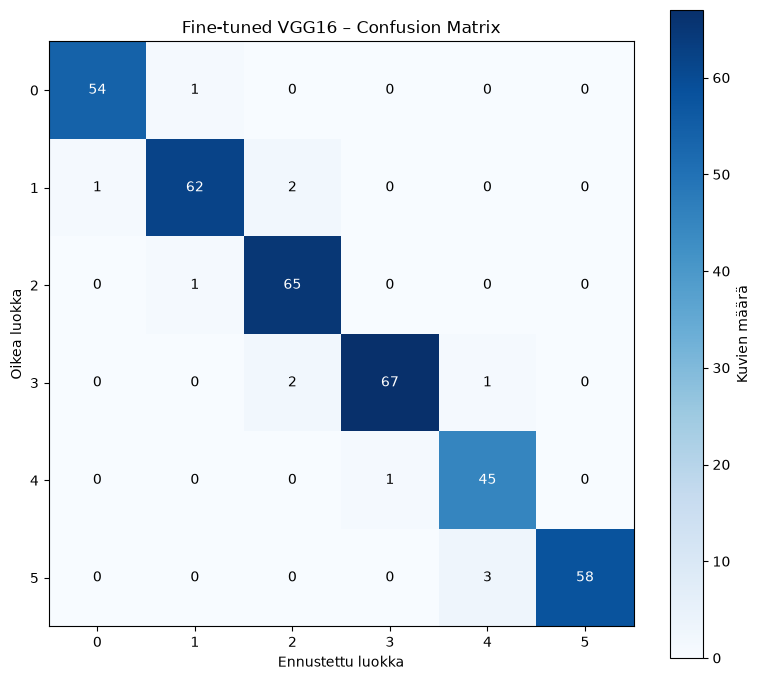

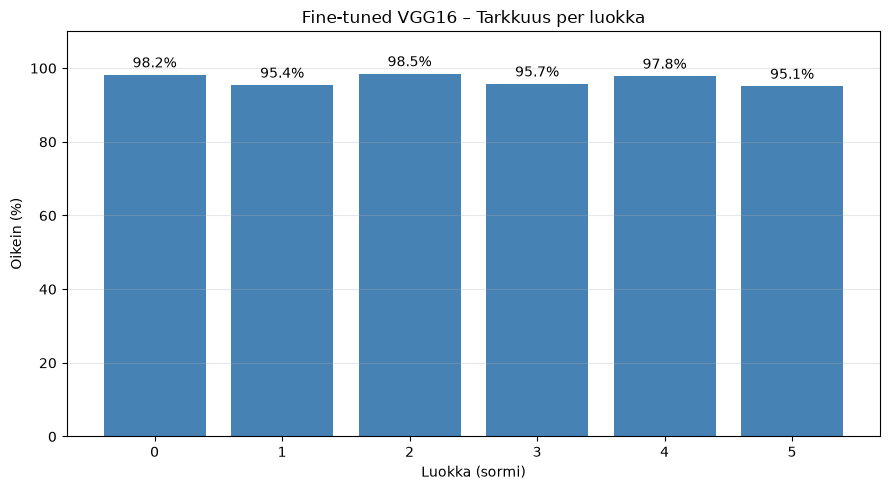


Luokka | Oikein | Yhteensä | Tarkkuus
---------------------------------------------
     0  |    54  |     55   |   98.2%
     1  |    62  |     65   |   95.4%
     2  |    65  |     66   |   98.5%
     3  |    67  |     70   |   95.7%
     4  |    45  |     46   |   97.8%
     5  |    58  |     61   |   95.1%


In [18]:
import matplotlib.pyplot as plt

all_probs = []
all_true = []
all_images = []

for images, labels in test_dataset:
    probs = model_ft.predict(images, verbose=0)
    all_probs.append(probs)
    all_true.append(labels.numpy())
    all_images.append(images.numpy())

y_probs = np.concatenate(all_probs)
y_true = np.concatenate(all_true)
y_pred = np.argmax(y_probs, axis=1)
x_test = np.concatenate(all_images) 

print(f"Kuvia: {len(y_true)}")
print(f"Oikein: {np.sum(y_true == y_pred)} / {len(y_true)}")
print(f"Test accuracy: {np.mean(y_true == y_pred) * 100:.2f}%")

# Confusion matrix
cm = np.zeros((num_classes, num_classes), dtype=int)
for t, p in zip(y_true, y_pred):
    cm[t, p] += 1

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(np.arange(num_classes))
ax.set_yticks(np.arange(num_classes))
ax.set_xticklabels(class_names)
ax.set_yticklabels(class_names)
ax.set_xlabel("Ennustettu luokka")
ax.set_ylabel("Oikea luokka")
ax.set_title("Fine-tuned VGG16 – Confusion Matrix")
fig.colorbar(im, ax=ax, label="Kuvien määrä")
for i in range(num_classes):
    for j in range(num_classes):
        ax.text(
            j, i, str(cm[i, j]),
            ha="center", va="center",
            color="white" if cm[i, j] > cm.max() / 2 else "black"
        )
plt.tight_layout()
plt.show()

# Luokkakohtaiset tarkkuudet
correct = np.zeros(num_classes, dtype=int)
total = np.zeros(num_classes, dtype=int)
for i in range(num_classes):
    mask = (y_true == i)
    total[i] = np.sum(mask)
    correct[i] = np.sum(y_pred[mask] == i)

accuracy = np.divide(
    correct, total,
    out=np.zeros(num_classes, dtype=float),
    where=total != 0
) * 100

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(class_names, accuracy, color="steelblue")
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set_xlabel("Luokka (sormi)")
ax.set_ylabel("Oikein (%)")
ax.set_title("Fine-tuned VGG16 – Tarkkuus per luokka")
ax.set_ylim(0, 110)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("\nLuokka | Oikein | Yhteensä | Tarkkuus")
print("-" * 45)
for i in range(num_classes):
    print(f"  {class_names[i]:>4}  |  {correct[i]:>4}  |   {total[i]:>4}   |  {accuracy[i]:>5.1f}%")

Kaikki luokkakohtaiset tarkkuudet ovat yli 95 %. Paras on luokka 2 (98.5 %) ja heikoimmat luokka 5 (95.1 %) sekä luokka 1 (95.4 %). FE-mallin heikoimmat luokat 2 ja 3 paranivat selvästi: luokka 2 noin 80.3 %:sta 98.5 %:iin ja luokka 3 noin 82.9 %:sta 95.7 %:iin. Fine-tuning auttoi siis erottamaan aiempaa paremmin samankaltaisia sormimääriä.

### 4.3 Väärin luokitellut kuvat

Näytetään satunnaisotos väärin luokitelluista testikuvista. Kuvista näkee,
menevätkö virheet vierekkäisiin sormimääriin.

Väärin luokiteltuja: 12 / 363


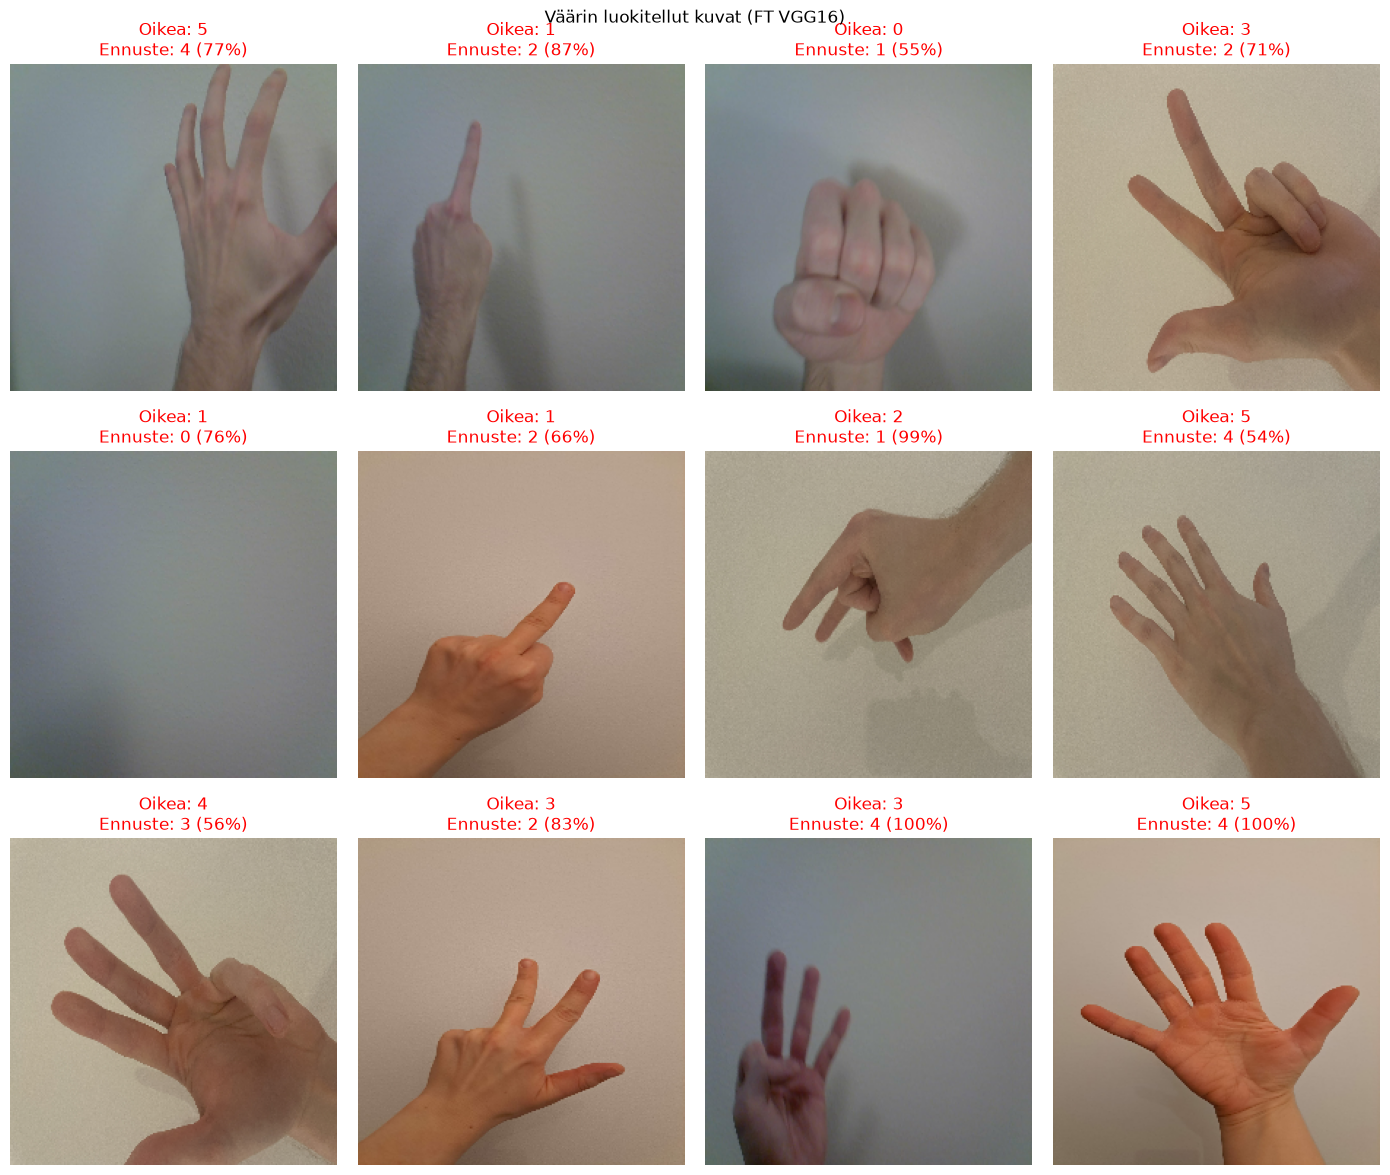

In [19]:
wrong_idx = np.where(y_true != y_pred)[0]
print(f"Väärin luokiteltuja: {len(wrong_idx)} / {len(y_true)}")

rng = np.random.default_rng(0)
show_idx = rng.choice(wrong_idx, size=min(12, len(wrong_idx)), replace=False)

n_cols = 4
n_rows = (len(show_idx) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 4 * n_rows))
axes = axes.flatten()

for i, idx in enumerate(show_idx):
    ax = axes[i]
    ax.imshow(x_test[idx].astype("uint8"))
    true_class = int(y_true[idx])
    pred_class = int(y_pred[idx])
    conf = y_probs[idx][pred_class]
    ax.set_title(
        f"Oikea: {class_names[true_class]}\n"
        f"Ennuste: {class_names[pred_class]} ({conf:.0%})",
        color="red"
    )
    ax.axis("off")

for j in range(len(show_idx), len(axes)):
    axes[j].axis("off")

plt.suptitle("Väärin luokitellut kuvat (FT VGG16)")
plt.tight_layout(h_pad=3.0, w_pad=1.5)
plt.show()

Väärin luokiteltuja kuvia on 12 / 363 eli noin 3.3 %. Määrä on pieni, joten yksittäisistä virheistä ei voi tehdä vahvoja johtopäätöksiä. Virheet näyttävät keskittyvän vierekkäisiin sormimääriin, ja myös kätisyys, sormien asento sekä valaistus voivat vaikuttaa. Vähäinen virhemäärä tukee sitä, että fine-tuning paransi mallin erottelukykyä.

### 4.4 Yksittäisen kuvan ennuste

Näytetään kolme satunnaista testikuvaa ja niiden ennustetodennäköisyydet.

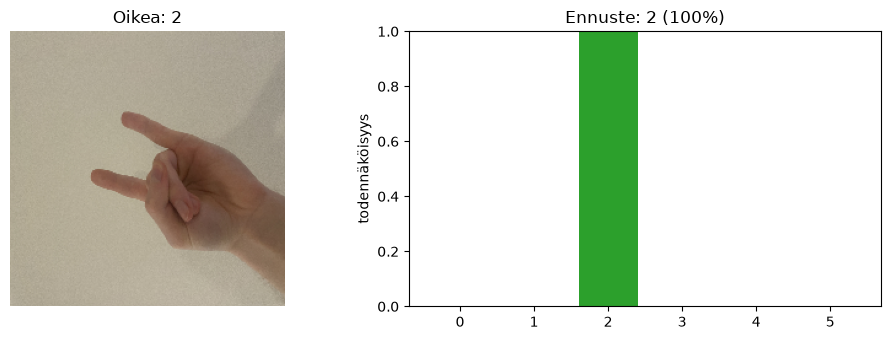

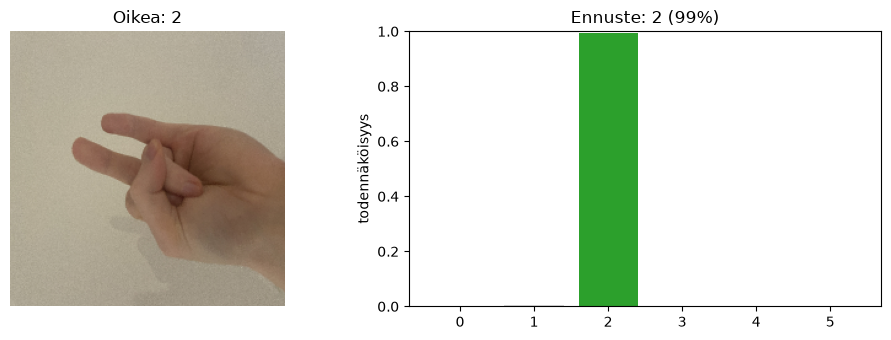

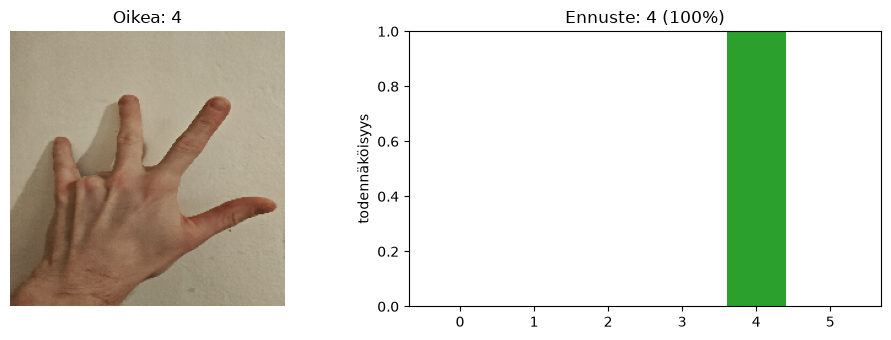

In [24]:
def plot_prediction(idx):
    pred = int(y_pred[idx])
    true = int(y_true[idx])

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))

    ax1.imshow(x_test[idx].astype("uint8"))
    ax1.axis("off")
    ax1.set_title(f"Oikea: {class_names[true]}")

    colors = ["lightgray"] * num_classes
    colors[pred] = "tab:red" if pred != true else "tab:green"
    ax2.bar(range(num_classes), y_probs[idx], color=colors)
    ax2.set_xticks(range(num_classes))
    ax2.set_xticklabels(class_names, rotation=0)
    ax2.set_ylim(0, 1)
    ax2.set_ylabel("todennäköisyys")
    ax2.set_title(f"Ennuste: {class_names[pred]} ({y_probs[idx][pred]:.0%})")

    plt.tight_layout()
    plt.show()

# Näytetään 3 satunnaista testikuvaa
rng2 = np.random.default_rng(1)
for idx in rng2.choice(len(y_true), size=3, replace=False):
    plot_prediction(idx)

Kaikki kolme esimerkkiä menivät oikein 100 %:n varmuudella. Otos on vain kolme kuvaa, joten tämä ei yksinään kerro mallin yleisestä varmuudesta — koko testijoukolla tarkkuus oli 96.69 %. Korkea varmuus on silti linjassa sen kanssa, että fine-tuning paransi erottelukykyä FE-malliin verrattuna.

### 4.5 Classification report

Yhteenveto per luokka: precision, recall ja F1-score.

In [20]:
from sklearn.metrics import classification_report

print(classification_report(
    y_true, y_pred,
    target_names=class_names,
    digits=4
))

              precision    recall  f1-score   support

           0     0.9818    0.9818    0.9818        55
           1     0.9688    0.9538    0.9612        65
           2     0.9420    0.9848    0.9630        66
           3     0.9853    0.9571    0.9710        70
           4     0.9184    0.9783    0.9474        46
           5     1.0000    0.9508    0.9748        61

    accuracy                         0.9669       363
   macro avg     0.9660    0.9678    0.9665       363
weighted avg     0.9679    0.9669    0.9671       363



Kaikkien luokkien precision, recall ja F1-score ovat korkeita. Heikoimmat F1-arvot ovat luokilla 4 (0.9474) ja 1 (0.9612), mutta erot luokkien välillä ovat pieniä. FE-malliin verrattuna luokkien 2 ja 3 tunnusluvut paranivat selvästi. Mikään luokka ei jää selvästi heikommaksi.

### 4.6 Koulutuskäyrät

Nähdään, miten loss ja accuracy kehittyivät fine-tuningin aikana.

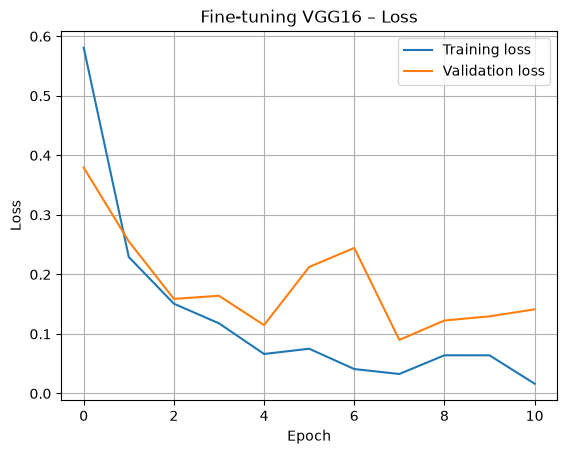

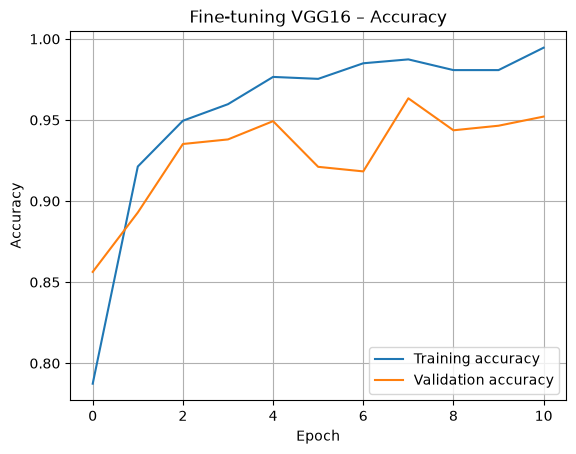

In [21]:
plt.plot(history_ft.history["loss"], label="Training loss")
plt.plot(history_ft.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Fine-tuning VGG16 – Loss")
plt.legend()
plt.grid(True)
plt.show()

plt.plot(history_ft.history["accuracy"], label="Training accuracy")
plt.plot(history_ft.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Fine-tuning VGG16 – Accuracy")
plt.legend()
plt.grid(True)
plt.show()

Kuvista näkee, että training-käyrä ohittaa validation-käyrän jo heti ensimmäisen epookin jälkeen: training loss laskee validation lossin alle ja training accuracy nousee validation accuracyn yli. Malli oppii harjoitusdatan nopeasti. Validation-käyrät kuitenkin heiluvat ja kääntyvät lopussa hieman huonommiksi, mikä viittaa lievään ylisovittumiseen. EarlyStopping palautti parhaan epookin (E8) painot, joilla test accuracy 96.7 % on lähellä validation accuracya 96.3 %.

### 4.7 Vertailu: Feature Extraction vs. Fine-tuning

Vedetään yhteen FE- ja FT-mallien testitulokset ja katsotaan, kuinka paljon fine-tuning paransi tulosta.
FE-luvut saadaan samasta ajosta, joten vertailu on suora.

In [22]:
print("Feature Extraction:")
print(f"  test loss:     {test_loss_fe:.4f}")
print(f"  test accuracy: {test_acc_fe * 100:.2f} %")

print("\nFine-tuned:")
print(f"  test loss:     {test_loss_ft:.4f}")
print(f"  test accuracy: {test_acc_ft * 100:.2f} %")

print("\nErot:")
print(f"  accuracy parani {(test_acc_ft - test_acc_fe) * 100:+.2f} prosenttiyksikköä")
print(f"  loss muuttui {(test_loss_ft - test_loss_fe):+.4f}")

Feature Extraction:
  test loss:     0.3635
  test accuracy: 88.43 %

Fine-tuned:
  test loss:     0.1379
  test accuracy: 96.69 %

Erot:
  accuracy parani +8.26 prosenttiyksikköä
  loss muuttui -0.2255


Fine-tuning paransi testitarkkuutta 8.26 prosenttiyksikköä (88.43 % -> 96.69 %) ja pienensi häviötä yli puoleen (0.3635 -> 0.1379). Koska FE- ja FT-malli arvioitiin samalla testijoukolla, vertailu on reilu. Ylimmän konvoluutioblokin avaaminen oli siis hyödyllistä tälle dataselille.

In [23]:
import json
import pandas as pd

metrics_ft = {
    "model": "fine_tuned_vgg16",
    "image_size": 224,
    "class_names": list(class_names),
    "test_loss": float(test_loss_ft),
    "test_accuracy": float(test_acc_ft),
    "confusion_matrix": cm.tolist(),
    "per_class_accuracy": accuracy.tolist(),
    "per_class_correct": correct.tolist(),
    "per_class_total": total.tolist(),
    # FE-baseline samasta ajosta vertailua varten
    "fe_baseline_loss": float(test_loss_fe),
    "fe_baseline_accuracy": float(test_acc_fe),
}
with open("metrics_ft.json", "w") as f:
    json.dump(metrics_ft, f, indent=2)

pd.DataFrame(history_ft.history).to_csv("history_ft.csv", index=False)

np.savez(
    "test_predictions_ft.npz",
    y_true=y_true,
    y_pred=y_pred,
    y_probs=y_probs,
)

print("Tallennettu: metrics_ft.json, history_ft.csv, test_predictions_ft.npz")

Tallennettu: metrics_ft.json, history_ft.csv, test_predictions_ft.npz
